# Adaptive Traffic Signal Control
## Reproducing the experimental results

This notebook explains how the results were obtained from saved experiments: traffic forecasting, baseline control, safety-weighted rewards, a time-without-green constraint, and policy distillation.

We reconstruct control metrics from **258 test runs**, compare controllers on matched demand scenarios, and calculate the percentage improvements reported in the paper. We also recompute the historical-average and persistence forecasts on the complete PeMS08 test split.

The notebook analyses previously completed experiments; it does not retrain neural networks or rerun SUMO. Full neural forecasting scores are read from saved evaluation summaries. All inputs are included in `evidence/`, and all cell outputs are saved.

Run the cells in order, or select **Restart Kernel → Run All**. The HTML version provides the same results without Jupyter.

In [1]:
from pathlib import Path
import json, hashlib, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from IPython.display import display, Markdown

BASE = Path.cwd()
if not (BASE / 'evidence').exists() and (BASE / 'notebook/evidence').exists():
    BASE = BASE / 'notebook'
E = BASE / 'evidence'
assert E.is_dir(), 'Open the notebook from the Notebook folder containing evidence/'
def read(path): return json.loads((E / path).read_text(encoding='utf-8'))
def frame(pattern):
    return pd.DataFrame([{**json.loads(p.read_text(encoding='utf-8')), 'source': p.relative_to(E).as_posix()} for p in sorted(E.glob(pattern))])
plt.rcParams.update({'figure.figsize': (10,4), 'axes.spines.top':False, 'axes.spines.right':False, 'font.family':'DejaVu Sans'})
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
D='delay_per_requested_vehicle_s'; C='conflicts_per_1000_arrivals'
loads=[.4,.7,.95]
names={'webster':'Webster','max_pressure':'Max Pressure','forecast_rule':'Forecast rule',
       'd3qn_no_forecast':'D3QN','d3qn_forecast':'D3QN + forecast','d3qn_safety':'Safety w=0.5',
       'd3qn_original':'Original + forecast','d3qn_guard_only':'Guard only',
       'd3qn_guard_trained':'Guard + training','guarded':'Guarded','improved':'Distilled'}
print('Python:', platform.python_version(), '| numpy:',np.__version__, '| pandas:',pd.__version__)

Python: 3.12.14 | numpy: 2.5.4 | pandas: 3.0.1


## 1. Data and experimental design

The analysis uses a snapshot of the project artifacts. `evidence/manifest.json` records the SHA-256 hashes of the included source files. These hashes identify the analysis inputs; they do not establish that the complete project matches the historical commit cited in the paper.

| Stage | Controllers | Demand seeds | Loads | Test runs |
|---|---:|---|---|---:|
| 1: original controllers | 5 | 200–209 | 0.40, 0.70, 0.95 | 150 |
| 2: guard and continued training | 5 | 1000–1003 | 0.40, 0.70, 0.95 | 60 |
| 3a: one distilled student | 4 | 1110–1111 | 0.40, 0.70, 0.95 | 24 |
| 3b: load-specific student selection | 4 | 1120–1121 | 0.40, 0.70, 0.95 | 24 |

Tuning and validation runs are separate. Each test run measures one hour after warm-up. Demand seeds vary the traffic scenario; they do not represent independently trained policies. Stage 1 uses one training seed per policy.

The next cell checks file integrity, scenario coverage, duplicate runs, measurement duration, collisions and teleports. For Stage 3, route hashes also verify that controllers face identical demand within each matched scenario.

In [2]:
manifest=read('manifest.json')
bad=[r['path'] for r in manifest if hashlib.sha256((E/r['path']).read_bytes()).hexdigest()!=r['sha256']]
assert not bad, bad
s1=frame('artifacts/evaluation/test_*.json')
tune=frame('artifacts/evaluation/tune_*.json')
s2=frame('artifacts/continuation/evaluation/*.json')
s3a=frame('artifacts/improvement/test/*.json')
s3b=frame('artifacts/improvement/test_by_load/*.json')
stages={'1':s1,'2':s2,'3a':s3a,'3b':s3b}
expected_seeds={'1':set(range(200,210)),'2':set(range(1000,1004)),'3a':{1110,1111},'3b':{1120,1121}}
inventory=[]
for stage,df in stages.items():
    assert not df.duplicated(['controller','saturation','seed']).any()
    assert set(df.seed)==expected_seeds[stage]
    assert set(df.saturation)==set(loads)
    for _,g in df.groupby(['controller','saturation']): assert set(g.seed)==expected_seeds[stage]
    assert (df.elapsed_s==3600).all()
    assert (df.split=='test').all()
    inventory.append({'stage':stage,'controllers':df.controller.nunique(),'seeds':sorted(df.seed.unique()),'runs':len(df),'collisions':df.collision_vehicle_events.sum(),'teleports':df.teleports.sum()})
inventory=pd.DataFrame(inventory)
display(inventory)
assert list(inventory.runs)==[150,60,24,24]
assert inventory.runs.sum()==258
assert inventory[['collisions','teleports']].to_numpy().sum()==0
print('SHA-256 verified:',len(manifest),'files. Tuning:',len(tune),'runs.')
# Verify identical demand within matched Stage 3 scenarios using route hashes.
for df in [s3a,s3b]:
    assert df.route_sha256.notna().all()
    assert (df.groupby(['seed','saturation']).route_sha256.nunique()==1).all()

SHA-256 verified: 353 files. Tuning: 20 runs.


,stage,controllers,seeds,runs,collisions,teleports
0,1,5,"[200, 201, 202, 203, 204, 205, 206, 207, 208, ...",150,0,0
1,2,5,"[1000, 1001, 1002, 1003]",60,0,0
2,3a,4,"[1110, 1111]",24,0,0
3,3b,4,"[1120, 1121]",24,0,0


## 2. Metric definitions

For run $r$, delay per requested vehicle is

$$D_r=\frac{I_r}{\max(N_{\mathrm{requested},r},1)},$$

where $I_r$ is the accumulated time loss inside the network plus waiting outside it, in vehicle-seconds. This is a finite-window measure, rather than the complete trip delay of vehicles that finish their journeys.

Conflicts per 1,000 arrivals are

$$C_r=\frac{1000\,n_{\mathrm{TTC},r}}{\max(N_{\mathrm{arrived},r},1)}.$$

A TTC event starts when a same-lane vehicle pair enters $0<TTC<1.5$ seconds. Re-entry counts as a new event. This is a surrogate conflict measure, not a crash count.

Reported group values are **means of run-level metrics**. Standard deviation uses $n-1$ in the denominator and describes scenario variability; it is not a confidence interval. Percentage change is

$$100\left(\frac{\bar D_{\mathrm{new}}}{\bar D_{\mathrm{baseline}}}-1\right).$$

Negative change indicates lower delay. Percentage reduction has the opposite sign. The ratio of means is not generally equal to the mean of individual percentage changes.

| Field | Interpretation |
|---|---|
| `mean_queue_vehicles` | Mean stopped-vehicle count over simulation steps |
| `throughput` | Vehicles leaving the network during the window, including possible warm-up vehicles |
| `pending_insertion` | Vehicles still waiting to enter at the end of the window |
| `co2_kg` | Total emissions during the window, rather than emissions per vehicle |

Implementation: `evidence/atsc/environment.py`. The following checks reconstruct delay, normalized conflicts and mean queue from the saved totals.

In [3]:
all_runs=pd.concat([df.assign(stage=k) for k,df in stages.items()],ignore_index=True)
formula_checks=[]
for label,actual,expected in [
    ('delay = integral/requested',all_runs[D],all_runs.integrated_delay_vehicle_s/all_runs.requested_evaluation_vehicles.clip(lower=1)),
    ('TTC = 1000*events/arrivals',all_runs[C],1000*all_runs.conflicts/all_runs.throughput.clip(lower=1)),
    ('queue = waiting_time/elapsed',all_runs.mean_queue_vehicles,all_runs.waiting_vehicle_s/all_runs.elapsed_s)]:
    err=np.max(np.abs(actual-expected))
    formula_checks.append({'formula':label,'max_abs_error':err})
    np.testing.assert_allclose(actual,expected,rtol=1e-10,atol=1e-8)
display(pd.DataFrame(formula_checks))
example=s1[(s1.controller=='d3qn_forecast')&(s1.seed==200)&(s1.saturation==.7)].iloc[0]
print(f"Example {example['source']}: {example.integrated_delay_vehicle_s:.6f} / {example.requested_evaluation_vehicles} = {example[D]:.6f} s")
print(f'TTC: 1000 × {example.conflicts} / {example.throughput} = {example[C]:.6f}')

Example artifacts/evaluation/test_d3qn_forecast_200_0.70.json: 524375.013105 / 3362 = 155.971152 s
TTC: 1000 × 1822 / 3392 = 537.146226


,formula,max_abs_error
0,delay = integral/requested,0.0000
1,TTC = 1000*events/arrivals,0.0000
2,queue = waiting_time/elapsed,0.0000


## 3. RQ1: traffic forecasting

PeMS04 contains 307 sensors and PeMS08 contains 170. Each sample uses 12 five-minute observations to predict the next three intervals: 5, 10 and 15 minutes ahead. The chronological train/validation/test split is 60/20/20. Normalization uses training data only; training and validation use stride 3, while testing uses stride 1.

**MAE** averages absolute errors across windows, horizons and sensors. **RMSE** is the square root of the pooled mean squared error. **MAPE** includes only positive targets.

The first table reads full test scores and training times from saved JSON files. Neural predictions are not recomputed here. Each `*_trace.npz` contains only the first 288 test windows for one sensor and is used solely for illustration.

We then independently recompute the PeMS08 historical-average and persistence baselines from the supplied NPZ data. PeMS04 raw data was not included in the provided project, so its full forecast errors cannot be independently recomputed here. Training times are historical wall-clock measurements, including validation.

SUMO windows: {'training_windows': 264, 'validation_windows': 88, 'test_windows': 88}


,dataset,model,mae,rmse,mape_nonzero_percent,training_seconds,test_samples,nodes
3,PEMS04,mlp,20.1653,31.9216,13.3480,5.4266,3397,307
2,PEMS04,lstm,20.4855,32.4056,13.5148,122.1363,3397,307
0,PEMS04,gru,20.9473,33.1402,14.0880,148.7173,3397,307
5,PEMS04,tgcn,21.4707,33.9372,14.4846,90.8326,3397,307
4,PEMS04,persistence,22.8307,36.6262,14.9846,0.0274,3397,307
1,PEMS04,ha,38.8626,59.6475,27.8450,0.0633,3397,307
9,PEMS08,mlp,16.0398,24.7526,10.5268,2.6805,3570,170
8,PEMS08,lstm,16.5038,25.3488,10.3953,62.0933,3570,170
6,PEMS08,gru,16.7950,25.7603,11.3709,46.4336,3570,170
11,PEMS08,tgcn,17.1984,26.3723,11.2360,51.8907,3570,170


,dataset,T-GCN reduction vs persistence %,T-GCN increase vs MLP %
0,PEMS04,5.9567,6.4736
1,PEMS08,2.8432,7.2230


,dataset,model,best_epoch,last_epoch
0,PEMS04,gru,6,6
1,PEMS04,lstm,6,6
2,PEMS04,mlp,6,6
3,PEMS04,tgcn,6,6
4,PEMS08,gru,6,6
5,PEMS08,lstm,6,6
6,PEMS08,mlp,6,6
7,PEMS08,tgcn,6,6


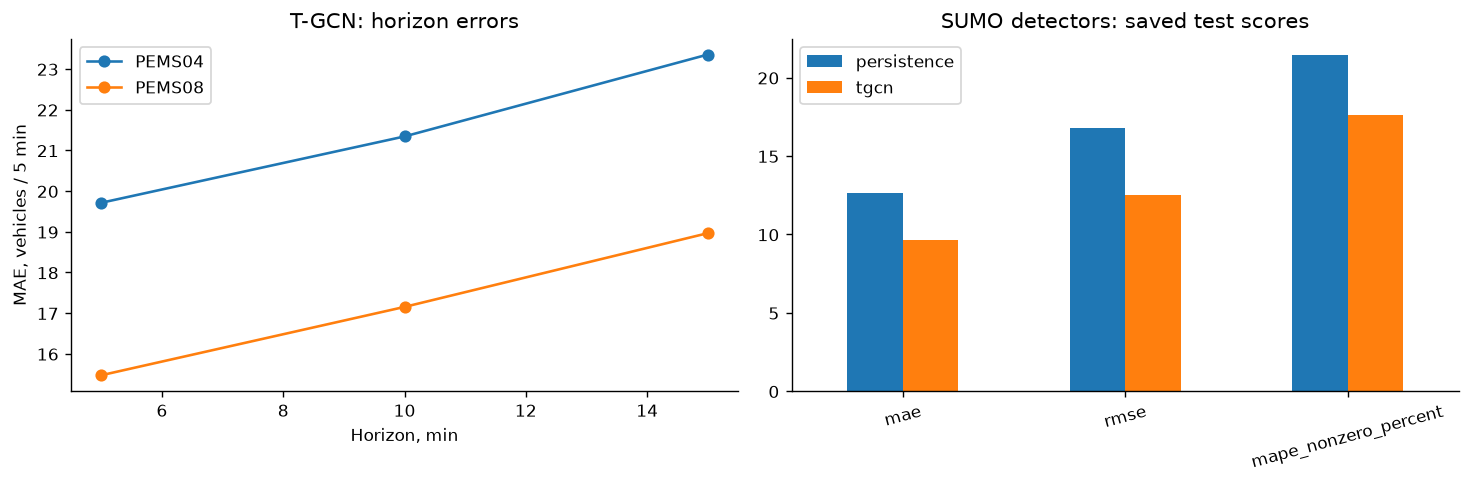

,persistence,tgcn,reduction_%
mae,12.6316,9.6773,23.3880
rmse,16.7694,12.4870,25.5369
mape_nonzero_percent,21.4290,17.6113,17.8156


In [4]:
forecast=frame('artifacts/forecast/PEMS*/*.json')
display(forecast[['dataset','model','mae','rmse','mape_nonzero_percent','training_seconds','test_samples','nodes']].sort_values(['dataset','mae']))
rows=[]
for ds,g in forecast.groupby('dataset'):
    f=g.set_index('model')
    rows.append({'dataset':ds,'T-GCN reduction vs persistence %':100*(1-f.loc['tgcn','mae']/f.loc['persistence','mae']),
                 'T-GCN increase vs MLP %':100*(f.loc['tgcn','mae']/f.loc['mlp','mae']-1)})
display(pd.DataFrame(rows))
epochs=[]
for r in forecast.to_dict('records'):
    if r['history']:
        best=min(r['history'],key=lambda h:h['validation_mae'])
        epochs.append({'dataset':r['dataset'],'model':r['model'],'best_epoch':best['epoch'],'last_epoch':r['history'][-1]['epoch']})
display(pd.DataFrame(epochs))
assert all(r['best_epoch']==6 for r in epochs)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ds,g in forecast[forecast.model=='tgcn'].groupby('dataset'):
    axes[0].plot([5,10,15],g.iloc[0].horizon_mae,marker='o',label=ds)
axes[0].set(xlabel='Horizon, min',ylabel='MAE, vehicles / 5 min',title='T-GCN: horizon errors'); axes[0].legend()
sim=read('artifacts/forecast/simulation_tgcn.json')
simdf=pd.DataFrame({k:sim[k] for k in ['persistence','tgcn']}).loc[['mae','rmse','mape_nonzero_percent']]
simdf.plot.bar(ax=axes[1],rot=15,title='SUMO detectors: saved test scores')
plt.tight_layout(); plt.show()
simdf['reduction_%']=100*(1-simdf.tgcn/simdf.persistence)
display(simdf)
print('SUMO windows:', {k:sim[k] for k in ['training_windows','validation_windows','test_windows']})

,model,metric,recomputed,saved,difference
0,ha,mae,36.3641,36.3641,0.0000
1,ha,rmse,54.1640,54.1640,0.0000
2,ha,mape_nonzero_percent,24.4540,24.4540,0.0000
3,persistence,mae,17.7017,17.7017,0.0000
4,persistence,rmse,27.3126,27.3126,0.0000
5,persistence,mape_nonzero_percent,10.9679,10.9679,0.0000


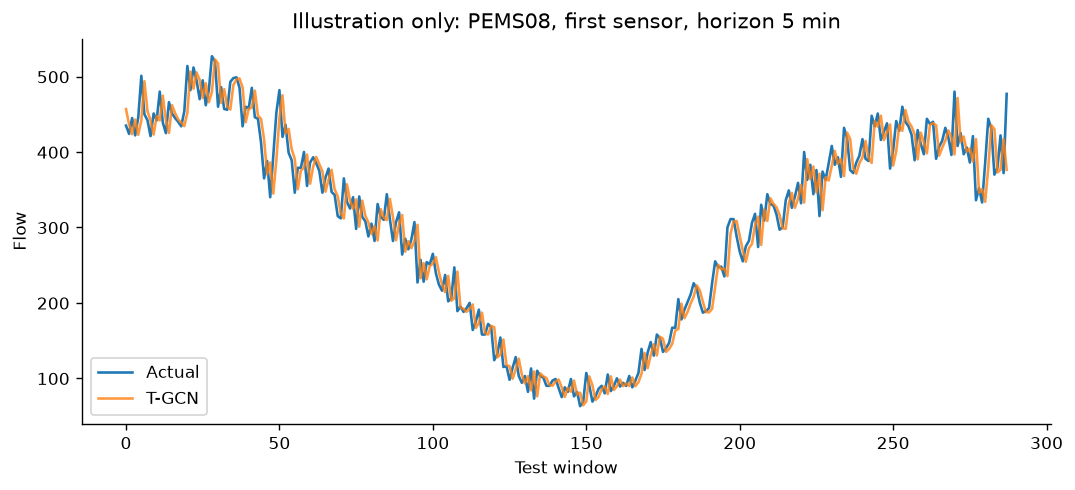

In [5]:
# Independently recompute two baselines on the full PeMS08 test split.
raw=np.load(E/'data/PEMS08.npz')['data'][:,:,0].astype('float32')
for i in range(len(raw)):
    bad=~np.isfinite(raw[i])|(raw[i]<0)
    raw[i,bad]=raw[i-1,bad] if i else 0
c1=int(.6*len(raw)); c2=int(.8*len(raw))
idx=np.arange(max(c2,12),len(raw)-2)
y=np.stack([raw[t:t+3] for t in idx])
slots=np.arange(c1)%288
ha=np.stack([raw[:c1][slots==s].mean(0) for s in range(288)])
def scores(y,p):
    e=p-y; mask=y>0
    return {'mae':float(np.abs(e).mean()),'rmse':float(np.sqrt((e*e).mean())),
            'mape_nonzero_percent':float((np.abs(e[mask])/y[mask]).mean()*100)}
baseline_audit=[]
for model in ['ha','persistence']:
    p=(np.stack([ha[(t+np.arange(3))%288] for t in idx]) if model=='ha' else
       np.stack([np.repeat(raw[t-1:t],3,axis=0) for t in idx]))
    saved=read(f'artifacts/forecast/PEMS08/{model}.json')
    for metric,value in scores(y,p).items():
        baseline_audit.append({'model':model,'metric':metric,'recomputed':value,'saved':saved[metric],'difference':value-saved[metric]})
        np.testing.assert_allclose(value,saved[metric],rtol=2e-6)
display(pd.DataFrame(baseline_audit))
del y,p,raw
trace=np.load(E/'artifacts/forecast/PEMS08/tgcn_trace.npz')
plt.plot(trace['actual'][:,0],label='Actual'); plt.plot(trace['predicted'][:,0],label='T-GCN',alpha=.8)
plt.title('Illustration only: PEMS08, first sensor, horizon 5 min'); plt.xlabel('Test window'); plt.ylabel('Flow'); plt.legend(); plt.show()

## 4. RQ2: original controllers

Each controller/load combination contains ten test scenarios. Three agents completed 30 training episodes each. The tables reconstruct the means and sample standard deviations directly from individual run files; error bars show one SD.

The two-sided Wilcoxon signed-rank test compares **paired delay differences at the same demand seed**, separately for each load. The paper reports six exploratory tests without multiplicity correction. We also calculate Holm-adjusted p-values for that family of six tests.

Statistical significance across demand scenarios does not establish robustness across independent training seeds. Effect sizes and variability must be considered alongside p-values.

,controller,episodes
0,d3qn_no_forecast,30
1,d3qn_forecast,30
2,d3qn_safety,30


delay_per_requested_vehicle_s                 \
                                                     mean      std count   
saturation controller                                                      
0.4000     d3qn_forecast                         160.8634 140.4031    10   
           d3qn_no_forecast                      180.7061 362.3091    10   
           forecast_rule                          50.3745   1.2402    10   
           max_pressure                           26.8085   2.4929    10   
           webster                                30.9609   3.5869    10   
0.7000     d3qn_forecast                         238.2946 113.0498    10   
           d3qn_no_forecast                      442.7348 419.4913    10   
           forecast_rule                          98.4587  29.6285    10   
           max_pressure                          216.2039  88.7593    10   
           webster                               108.9089  39.4853    10   
0.9500     d3qn_forecast                         816.8429 180.7010    10   
           d3qn_no_forecast                      754.6347 207.2538    10   
           forecast_rule                         676.1589 196.6544    10   
           max_pressure                          913.2822 185.5397    10   
           webster                               629.9251 180.6882    10   

                            mean_queue_vehicles                throughput  \
                                           mean      std count       mean   
saturation controller                                                       
0.4000     d3qn_forecast                83.9535  75.8898    10 2,116.3000   
           d3qn_no_forecast             78.6333 150.0656    10 2,007.3000   
           forecast_rule                24.3987   2.8379    10 2,191.5000   
           max_pressure                 10.5367   2.3140    10 2,204.5000   
           webster                      12.6906   2.9282    10 2,202.4000   
0.7000     d3qn_forecast               182.2777  85.7821    10 3,492.2000   
           d3qn_no_forecast            259.1631 172.8885    10 3,057.5000   
           forecast_rule                81.8538  31.3862    10 3,795.7000   
           max_pressure                135.0041  56.2045    10 3,563.4000   
           webster                      84.0525  36.1582    10 3,774.4000   
0.9500     d3qn_forecast               454.5841  35.5580    10 4,339.6000   
           d3qn_no_forecast            469.0563  32.2687    10 4,266.7000   
           forecast_rule               431.6478  36.9111    10 4,680.6000   
           max_pressure                401.0978  36.2984    10 4,062.1000   
           webster                     457.9578  33.1072    10 4,807.0000   

                                           conflicts_per_1000_arrivals  \
                                 std count                        mean   
saturation controller                                                    
0.4000     d3qn_forecast    234.1410    10                    587.1529   
           d3qn_no_forecast 460.8181    10                    537.6638   
           forecast_rule    232.1169    10                    559.5383   
           max_pressure     231.6248    10                    424.8657   
           webster          230.4234    10                    442.4909   
0.7000     d3qn_forecast    281.1444    10                    533.1775   
           d3qn_no_forecast 873.3022    10                    521.9874   
           forecast_rule    322.7149    10                    554.9104   
           max_pressure     126.6809    10                    484.1780   
           webster          293.9283    10                    530.2819   
0.9500     d3qn_forecast    142.3831    10                    217.8534   
           d3qn_no_forecast 515.7704    10                    274.3534   
           forecast_rule     40.2139    10                    278.4390   
           max_pressure     208.8383    10                    130.0272   
           web

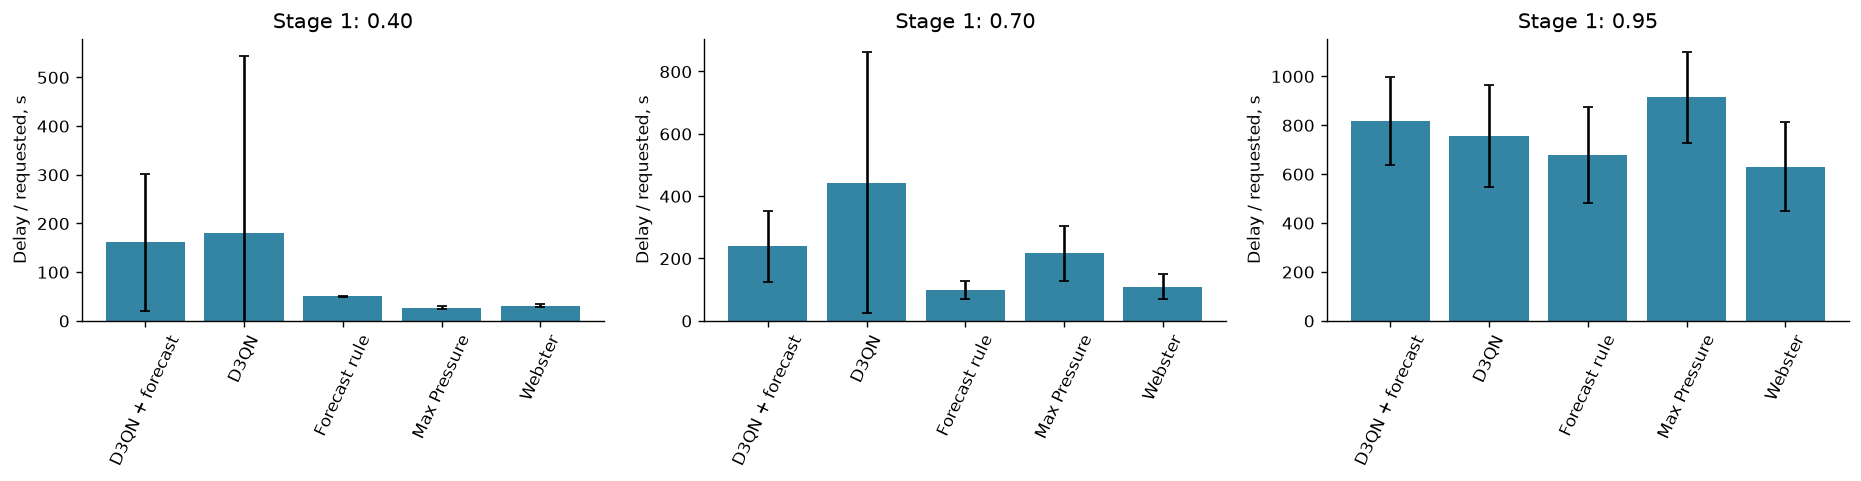

,comparison,saturation,n,mean_difference_s,change_%,p_two_sided,p_Holm
0,d3qn_forecast vs max_pressure,0.4000,10,134.0550,500.0471,0.0020,0.0117
1,d3qn_forecast vs max_pressure,0.7000,10,22.0907,10.2175,0.1602,0.3359
2,d3qn_forecast vs max_pressure,0.9500,10,-96.4393,-10.5596,0.0020,0.0117
3,d3qn_forecast vs d3qn_no_forecast,0.4000,10,-19.8426,-10.9806,0.0840,0.3359
4,d3qn_forecast vs d3qn_no_forecast,0.7000,10,-204.4402,-46.1767,0.1602,0.3359
5,d3qn_forecast vs d3qn_no_forecast,0.9500,10,62.2083,8.2435,0.0840,0.3359


In [6]:
metrics=[D,'mean_queue_vehicles','throughput',C,'pending_insertion']
training=[]
for name in ['d3qn_no_forecast','d3qn_forecast','d3qn_safety']:
    history=read(f'artifacts/control/{name}_seed0.json')
    training.append({'controller':name,'episodes':len(history)})
display(pd.DataFrame(training))
assert sum(x['episodes'] for x in training)==90
summary1=s1.groupby(['saturation','controller'])[metrics].agg(['mean','std','count'])
display(summary1)
def plot_stage(df,title):
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for load,ax in zip(loads,axes):
        g=df[df.saturation==load].groupby('controller')[D].agg(['mean','std'])
        ax.bar([names.get(x,x) for x in g.index],g['mean'],yerr=g['std'],capsize=3,color='#3485a4')
        ax.set(title=f'{title}: {load:.2f}',ylabel='Delay / requested, s',ylim=(0,None))
        ax.tick_params(axis='x',rotation=65)
    plt.tight_layout(); plt.show()
plot_stage(s1,'Stage 1')
def paired(df,new,base,load):
    p=df[df.saturation==load].pivot(index='seed',columns='controller',values=D)[[new,base]]
    assert not p.isna().any().any()
    return p
tests=[]
for base in ['max_pressure','d3qn_no_forecast']:
    for load in loads:
        p=paired(s1,'d3qn_forecast',base,load); d=p.iloc[:,0]-p.iloc[:,1]
        tests.append({'comparison':f'd3qn_forecast vs {base}','saturation':load,'n':len(d),
                      'mean_difference_s':d.mean(),'change_%':100*(p.iloc[:,0].mean()/p.iloc[:,1].mean()-1),
                      'p_two_sided':1. if np.allclose(d,0) else wilcoxon(d,alternative='two-sided').pvalue})
tests=pd.DataFrame(tests)
order=np.argsort(tests.p_two_sided.to_numpy())
adjusted=np.maximum.accumulate(tests.p_two_sided.to_numpy()[order]*(len(tests)-np.arange(len(tests))))
tests['p_Holm']=np.nan; tests.loc[order,'p_Holm']=np.minimum(adjusted,1)
saved=pd.DataFrame(read('artifacts/evaluation/paired_tests.json'))
merged=tests.merge(saved,on=['comparison','saturation'],suffixes=('_new','_saved'))
np.testing.assert_allclose(merged.p_two_sided_new,merged.p_two_sided_saved)
np.testing.assert_allclose(merged.mean_difference_s_new,merged.mean_difference_s_saved)
display(tests)

**Interpretation.** At load 0.70, forecasting reduces mean D3QN delay by about 46%, but the paired test does not establish a significant difference with ten scenarios. At 0.95, the forecast-aware agent performs worse than D3QN without forecasts, yet better than Max Pressure (exploratory p ≈ 0.002). There is no consistent advantage over both baselines across all loads.

## 5. RQ3: safety-weighted reward

The candidate with efficiency weight $w=0.5$ is compared with the efficiency-only agent ($w=1$) on tuning seeds 100–109 at load 0.70.

Acceptance requires **both** lower TTC conflicts and delay no greater than 1.05 times the reference delay. A conflict reduction alone is insufficient. These twenty tuning runs are excluded from the 258 test runs.

In [7]:
assert len(tune)==20 and set(tune.seed)==set(range(100,110))
assert set(tune.saturation)=={.7}
g=tune.groupby('controller')[[D,C,'throughput','pending_insertion']].mean()
ref=g.loc['d3qn_forecast']; safe=g.loc['d3qn_safety']
display(g)
delay_growth=100*(safe[D]/ref[D]-1); conflict_reduction=100*(1-safe[C]/ref[C])
gate=bool(safe[D]<=1.05*ref[D] and safe[C]<ref[C])
print(f'Delay increase: {delay_growth:.3f}%; TTC reduction: {conflict_reduction:.3f}%')
print(f'Maximum accepted delay: {1.05*ref[D]:.3f} s; observed: {safe[D]:.3f} s; gate = {gate}')
assert gate==read('artifacts/evaluation/safety_selection.json')['passes_delay_and_conflict_gate']
assert not gate

Delay increase: 280.023%; TTC reduction: 18.388%
Maximum accepted delay: 214.024 s; observed: 774.609 s; gate = False


,delay_per_requested_vehicle_s,conflicts_per_1000_arrivals,throughput,pending_insertion
controller,,,,
d3qn_forecast,203.8322,557.2798,"3,409.5000",18.9000
d3qn_safety,774.6086,454.8058,"2,407.0000",734.5000


## 6. RQ4: guard and continued training

Stage 2 separates three variants: original weights, the same weights with a guard, and the guarded agent after 30 additional training episodes. The guard limits the time an **approach receives no green** to 120 seconds; it does not bound an individual vehicle's travel time.

Checkpoints at additional episodes 0, 10, 20 and 30 are compared on validation seeds 500–502. The selected checkpoint is evaluated on seeds 1000–1003.

The reported 44.8% reduction at medium load compares the trained guarded agent with the original agent **within Stage 2**. Comparing it with Stage 1 would mix different demand scenarios.

,episode,validation_delay
0,0,169.4559
1,10,125.3653
2,20,118.0220
3,30,114.2959


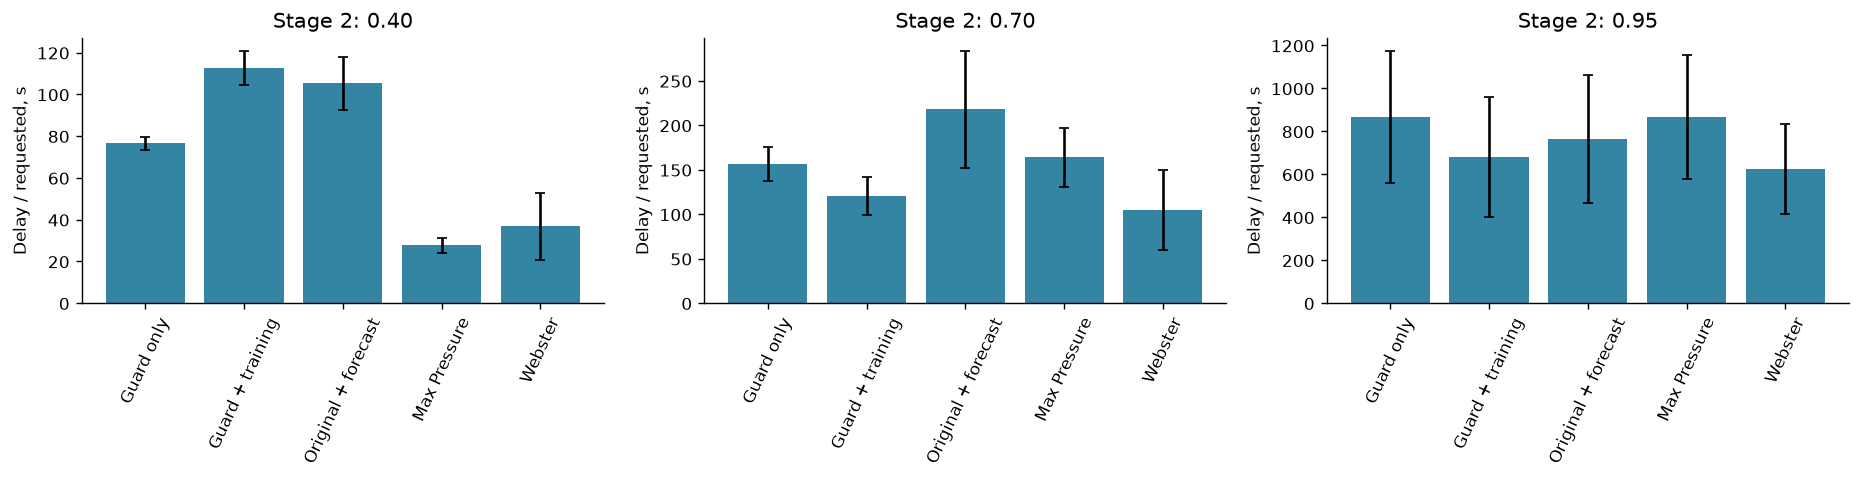

,load,guard_only vs original %,guard_trained vs original %,guard_trained vs guard_only %
0,0.4000,-27.2207,6.9455,46.9450
1,0.7000,-28.2044,-44.8036,-23.1201
2,0.9500,13.4930,-11.1088,-21.6770


mean        max
saturation controller                            
0.4000     d3qn_guard_only    118.7500   120.0000
           d3qn_guard_trained 118.5000   120.0000
           d3qn_original      532.2500   771.0000
           max_pressure       134.0000   250.0000
           webster             76.0000    76.0000
0.7000     d3qn_guard_only    118.5000   119.0000
           d3qn_guard_trained 118.2500   119.0000
           d3qn_original      757.0000 1,177.0000
           max_pressure       206.7500   505.0000
           webster             86.0000    86.0000
0.9500     d3qn_guard_only    118.2500   119.0000
           d3qn_guard_trained 118.2500   119.0000
           d3qn_original      563.5000   694.0000
           max_pressure       130.0000   261.0000
           webster            162.0000   162.0000

In [8]:
validation=[]
for p in sorted(E.glob('artifacts/continuation/validation_*.json')):
    r=json.loads(p.read_text()); value=np.mean([x[D] for x in r['runs']])
    np.testing.assert_allclose(value,r['mean_delay'])
    validation.append({'episode':r['episode'],'validation_delay':value})
validation=pd.DataFrame(validation)
display(validation)
selected=int(validation.loc[validation.validation_delay.idxmin(),'episode'])
assert selected==read('artifacts/continuation/selection.json')['episode']==30
plot_stage(s2,'Stage 2')
changes2=[]
means2=s2.groupby(['saturation','controller'])[D].mean().unstack()
for load,row in means2.iterrows():
    changes2.append({'load':load,'guard_only vs original %':100*(row.d3qn_guard_only/row.d3qn_original-1),
                     'guard_trained vs original %':100*(row.d3qn_guard_trained/row.d3qn_original-1),
                     'guard_trained vs guard_only %':100*(row.d3qn_guard_trained/row.d3qn_guard_only-1)})
display(pd.DataFrame(changes2))
display(s2.groupby(['saturation','controller']).max_without_green_s.agg(['mean','max']))
guarded=s2[s2.controller.isin(['d3qn_guard_only','d3qn_guard_trained'])]
assert (guarded.max_without_green_s<=120+1e-8).all()

## 7. Policy distillation and load-specific selection

Three students use continuation bonuses of 5, 15 and 30. Stage 3a selects one student by mean normalized validation delay. Stage 3b selects the lowest-delay student separately for each configured load. Validation uses seed 610 and a shorter 1,800-second measurement window at each load.

The load-specific rule was introduced after observing Stage 3a. Stage 3b therefore uses new test seeds 1120–1121, separate from 1110–1111. This is a staged investigation, not one fully prespecified experiment. Results from different stages should not be pooled as if they were identical trials.

The cells below reconstruct selection, compare stages, calculate improvements against each baseline, and show all six matched Stage 3b scenarios.

Per-load selection: {0.4: 5, 0.7: 30, 0.95: 30}


bonus,5,15,30
saturation,,,
0.4000,25.7065,32.1465,52.6817
0.7000,66.3110,63.7835,58.9609
0.9500,816.4012,765.1282,718.2377


,mean normalized validation delay
bonus,
5,1.0000
15,1.0499
30,1.2728


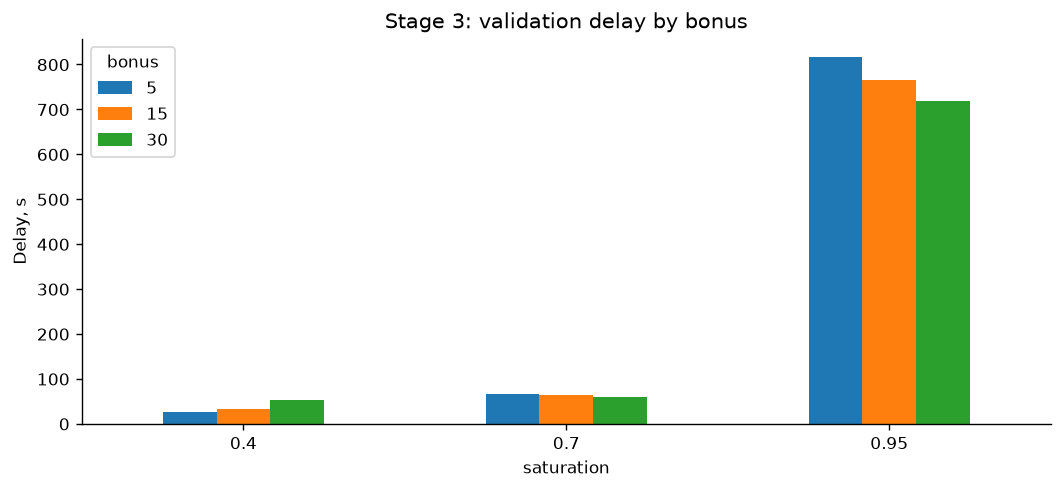

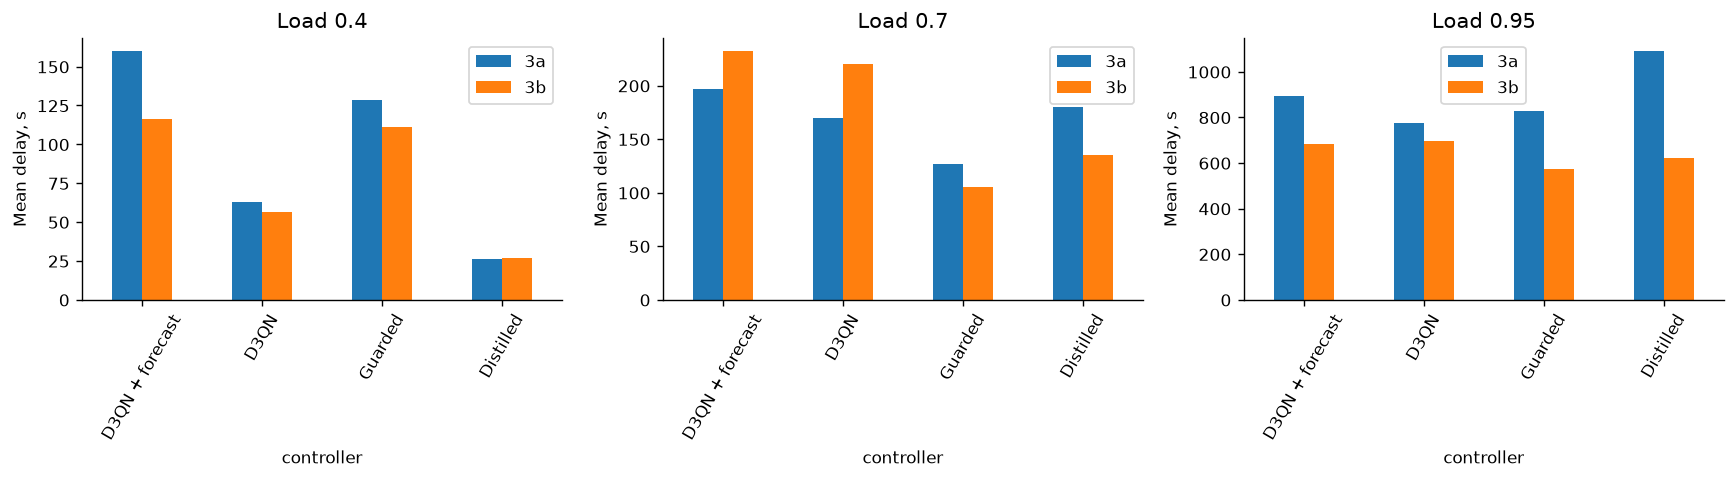

delay_per_requested_vehicle_s  \
saturation controller                                        
0.4000     d3qn_forecast                          116.4046   
           d3qn_no_forecast                        56.3886   
           guarded                                111.2408   
           improved                                27.0742   
0.7000     d3qn_forecast                          232.4932   
           d3qn_no_forecast                       220.0094   
           guarded                                105.6272   
           improved                               134.8966   
0.9500     d3qn_forecast                          682.4097   
           d3qn_no_forecast                       697.7078   
           guarded                                573.7879   
           improved                               620.6224   

                             mean_queue_vehicles  throughput  \
saturation controller                                          
0.4000     d3qn_forecast                 58.7728  2,098.0000   
           d3qn_no_forecast              26.5217  2,143.0000   
           guarded                       54.6728  2,092.5000   
           improved                      10.5621  2,160.0000   
0.7000     d3qn_forecast                191.5819  3,631.5000   
           d3qn_no_forecast             187.9344  3,603.0000   
           guarded                       86.5878  3,872.0000   
           improved                     101.2683  3,818.0000   
0.9500     d3qn_forecast                463.9467  4,306.5000   
           d3qn_no_forecast             475.1651  3,924.0000   
           guarded                      419.9492  4,594.0000   
           improved                     413.1494  4,490.0000   

                             pending_insertion     co2_kg  \
saturation controller                                       
0.4000     d3qn_forecast                0.0000   840.4037   
           d3qn_no_forecast             0.0000   649.3131   
           guarded                      0.0000   824.1048   
           improved                     0.0000   554.3984   
0.7000     d3qn_forecast               50.0000 2,118.6385   
           d3qn_no_forecast            72.0000 2,044.0264   
           guarded                      0.0000 1,460.5318   
           improved                     0.0000 1,614.5378   
0.9500     d3qn_forecast              819.0000 4,177.1973   
           d3qn_no_forecast         1,251.5000 3,937.5930   
           guarded                    535.0000 4,140.3731   
           improved                   583.5000 4,268.6342   

                             conflicts_per_1000_arrivals  switches  
saturation controller                                               
0.4000     d3qn_forecast                        609.6570  165.0000  
           d3qn_no_forecast                     512.7827  258.5000  
           guarded                              616.6546  153.5000  
           improved                             452.2900  277.0000  
0.7000     d3qn_forecast                        566.3932  139.0000  
           d3qn_no_forecast                     565.2326  110.5000  
           guarded                              555.2628  146.0000  
           improved                             530.3887  214.0000  
0.9500     d3qn_forecast                        236.4272  112.0000  
           d3qn_no_forecast                     311.6079   64.5000  
           guarded                              330.4324  123.0000  
           improved                             271.5968  146.5000

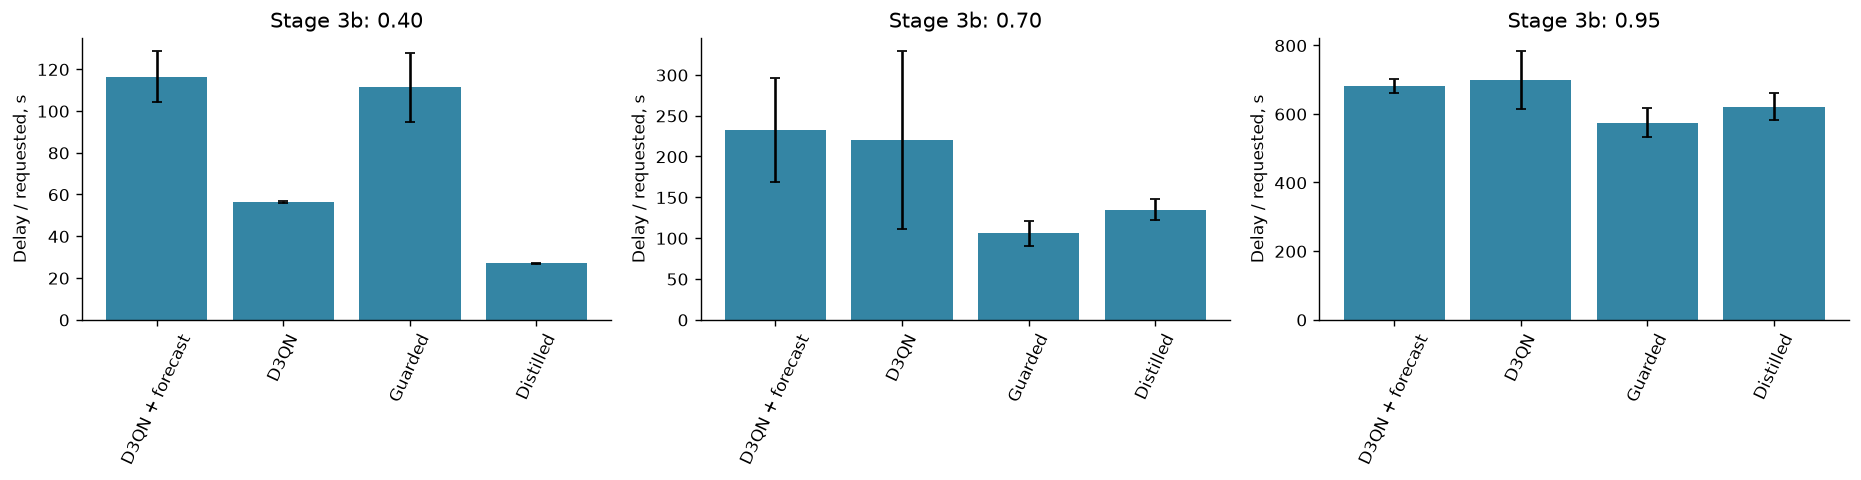

,stage,load,baseline,n,new_mean_s,base_mean_s,reduction_%
0,3a,0.4000,d3qn_no_forecast,2,26.0033,62.7430,58.5559
1,3a,0.4000,d3qn_forecast,2,26.0033,160.1621,83.7644
2,3a,0.4000,guarded,2,26.0033,128.4607,79.7578
3,3a,0.7000,d3qn_no_forecast,2,179.9391,169.8885,-5.9160
4,3a,0.7000,d3qn_forecast,2,179.9391,196.8773,8.6034
5,3a,0.7000,guarded,2,179.9391,126.3418,-42.4225
6,3a,0.9500,d3qn_no_forecast,2,"1,091.8387",776.8299,-40.5505
7,3a,0.9500,d3qn_forecast,2,"1,091.8387",894.8185,-22.0179
8,3a,0.9500,guarded,2,"1,091.8387",828.2717,-31.8213
9,3b,0.4000,d3qn_no_forecast,2,27.0742,56.3886,51.9865


,load,seed,D3QN,Distilled,change_%
0,0.4000,1120,56.5758,26.9364,-52.3888
1,0.4000,1121,56.2014,27.2119,-51.5815
2,0.7000,1120,296.8544,144.3599,-51.3701
3,0.7000,1121,143.1645,125.4333,-12.3852
4,0.9500,1120,757.4255,593.1065,-21.6944
5,0.9500,1121,637.9901,648.1383,1.5906


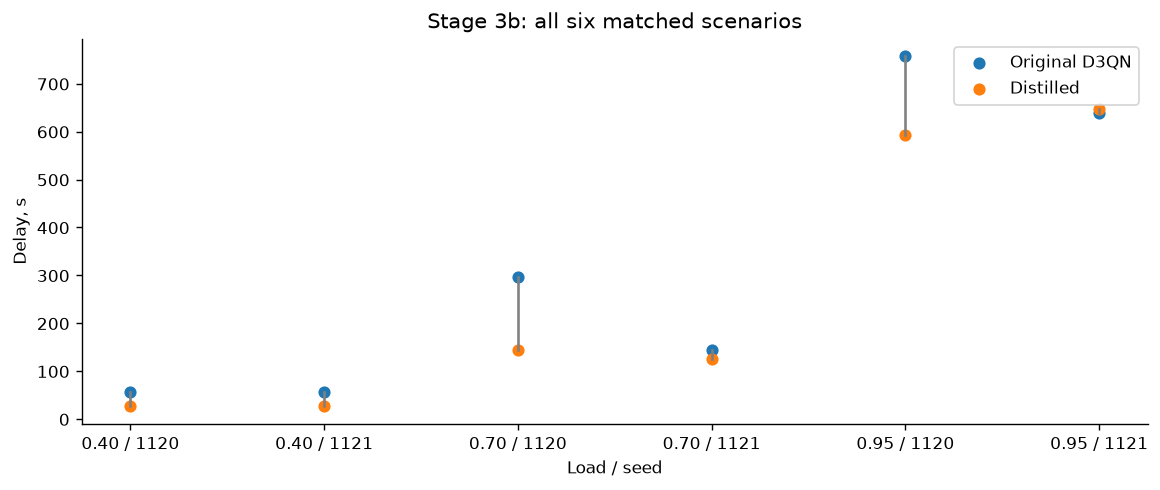

In [9]:
v3=frame('artifacts/improvement/validation_*.json')
v3['bonus']=v3.checkpoint.str.extract(r'candidate_(\d+)').astype(int)
v=v3.pivot(index='saturation',columns='bonus',values=D).sort_index()
display(v)
selection_scores=v.div(v[5],axis=0).mean()
display(selection_scores.to_frame('mean normalized validation delay'))
assert int(selection_scores.idxmin())==read('artifacts/improvement/selection.json')['bonus']
selection_by_load=v.idxmin(axis=1)
for load,bonus in selection_by_load.items():
    assert read('artifacts/improvement/load_selection.json')['checkpoints'][str(load)]==f'candidate_{bonus}.pt'
print('Per-load selection:',selection_by_load.to_dict())
v.plot.bar(rot=0,title='Stage 3: validation delay by bonus',ylabel='Delay, s'); plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
for load,ax in zip(loads,axes):
    comp=pd.DataFrame({stage:df[df.saturation==load].groupby('controller')[D].mean()
                       for stage,df in [('3a',s3a),('3b',s3b)]})
    comp.rename(index=names).plot.bar(ax=ax,rot=60,title=f'Load {load}',ylabel='Mean delay, s')
plt.tight_layout(); plt.show()
display(s3b.groupby(['saturation','controller'])[[D,'mean_queue_vehicles','throughput','pending_insertion','co2_kg',C,'switches']].mean())
plot_stage(s3b,'Stage 3b')
changes3=[]
for stage,df in [('3a',s3a),('3b',s3b)]:
    for load in loads:
        for base in ['d3qn_no_forecast','d3qn_forecast','guarded']:
            p=paired(df,'improved',base,load)
            changes3.append({'stage':stage,'load':load,'baseline':base,'n':len(p),
                             'new_mean_s':p.improved.mean(),'base_mean_s':p[base].mean(),
                             'reduction_%':100*(1-p.improved.mean()/p[base].mean())})
changes3=pd.DataFrame(changes3)
display(changes3)
pairs=[]
for load in loads:
    p=paired(s3b,'improved','d3qn_no_forecast',load)
    for seed,row in p.iterrows():
        pairs.append({'load':load,'seed':seed,'D3QN':row.d3qn_no_forecast,'Distilled':row.improved,
                      'change_%':100*(row.improved/row.d3qn_no_forecast-1)})
pairs=pd.DataFrame(pairs); display(pairs)
assert (pairs['change_%']<0).sum()==5
fig,ax=plt.subplots(figsize=(11,4))
for i,row in pairs.iterrows():
    ax.plot([i,i],[row.D3QN,row.Distilled],color='gray')
ax.scatter(pairs.index,pairs.D3QN,label='Original D3QN'); ax.scatter(pairs.index,pairs.Distilled,label='Distilled')
ax.set_xticks(pairs.index,[f"{r.load:.2f} / {int(r.seed)}" for r in pairs.itertuples()])
ax.set(xlabel='Load / seed',ylabel='Delay, s',title='Stage 3b: all six matched scenarios'); ax.legend(); plt.show()

**Interpretation.** The final 52.0%, 38.7% and 11.0% reductions compare mean delay with the original D3QN without forecasts. They do not imply improvement in every scenario: one of the six matched cases worsens by approximately 1.6%.

The guarded agent remains better than the distilled policy at loads 0.70 and 0.95. Webster, Max Pressure and the distillation teacher were not evaluated on these Stage 3 seeds, so these results do not establish superiority over them. With only two nonzero, untied pairs, the smallest possible exact two-sided Wilcoxon p-value is 0.5; Stage 3 comparisons are descriptive.

## 8. Reconstructing the headline results

Each percentage below is calculated from the run-level aggregates or saved forecast scores established above. The reported values are used only to check rounding; they are not inputs to the calculations.

In [10]:
claims=[]
def claim(label,actual,printed,decimals):
    claims.append({'claim':label,'computed':actual,'paper':printed,'matches_rounding':abs(actual-printed)<=.5*10**(-decimals)+1e-8})
for load,printed in zip(loads,[52.0,38.7,11.0]):
    row=changes3[(changes3.stage=='3b')&(changes3.load==load)&(changes3.baseline=='d3qn_no_forecast')].iloc[0]
    claim(f'Stage 3b reduction vs D3QN, load={load}',row['reduction_%'],printed,1)
claim('Safety TTC reduction %',conflict_reduction,18.4,1)
claim('Safety delay growth %',delay_growth,280,0)
claim('SUMO MAE reduction %',simdf.loc['mae','reduction_%'],23.4,1)
claim('Stage 2 medium-load reduction %',-pd.DataFrame(changes2).set_index('load').loc[.7,'guard_trained vs original %'],44.8,1)
claims=pd.DataFrame(claims); display(claims)
assert claims.matches_rounding.all()

,claim,computed,paper,matches_rounding
0,"Stage 3b reduction vs D3QN, load=0.4",51.9865,52.0000,True
1,"Stage 3b reduction vs D3QN, load=0.7",38.6860,38.7000,True
2,"Stage 3b reduction vs D3QN, load=0.95",11.0484,11.0000,True
3,Safety TTC reduction %,18.3883,18.4000,True
4,Safety delay growth %,280.0228,280.0000,True
5,SUMO MAE reduction %,23.3880,23.4000,True
6,Stage 2 medium-load reduction %,44.8036,44.8000,True


## 9. Conclusions and limitations

| Question | Evidence | Conclusion |
|---|---|---|
| RQ1: forecasting | T-GCN trails MLP, LSTM and GRU on PeMS; its saved SUMO MAE is 23.4% below persistence | Partly supported |
| RQ2: forecast-aware control | The effect depends on demand level and baseline | No consistent advantage |
| RQ3: safety reward | TTC decreases by 18.4%, but delay increases by about 280% | Acceptance criterion fails |
| RQ4: guard, training and distillation | Final mean delay improves over original D3QN at all loads; guarded remains better at medium and high loads | Partly supported |

These conclusions apply to the saved simulation experiments. The 88 SUMO forecast test windows cover loads 0.40 and 0.70. Each controller was trained with a limited budget and one training seed; Stage 3 has only two test scenarios per load. Zero simulated collisions do not demonstrate real-world safety.

This analysis checks arithmetic, aggregation and model selection. It does not reconstruct delay integrals from vehicle trajectories, rerun SUMO, or independently regenerate all neural predictions. The final policy also lacks a matched ablation that removes forecasts while retaining the same guard and distillation procedure.

The final cell exports the calculated tables for further analysis.

In [11]:
export=BASE/'audit_tables'; export.mkdir(exist_ok=True)
for name,df in {'inventory':inventory,'all_test_runs':all_runs,'forecast_metrics':forecast.drop(columns=['history']),
                'stage1_summary':summary1.reset_index(),'paired_tests':tests,'stage2_changes':pd.DataFrame(changes2),
                'stage3_changes':changes3,'stage3b_pairs':pairs,'headline_claims':claims}.items():
    df.to_csv(export/f'{name}.csv',index=False,encoding='utf-8-sig')
print(f'Analysis complete: {len(all_runs)} test runs.')
print('All headline percentages agree with the reported rounding.')

Analysis complete: 258 test runs.
All headline percentages agree with the reported rounding.
